# Logistic Regression Explanation 

Taking a set of  input parameters and giving a binary output, either 0 or 1 is logistic regression.  

This notebook teaches the Level 2 model to someone new to machine learning.

**Question:** Given four measurements about a lunch (queue_length, plate_waste_fraction, menu_board_kcal, handwriting_neatness), can a computer learn to predict whether it was a good lunch?

We will build the idea gradually: features and labels, weighted scores, sigmoid, probabilities, loss, gradients, gradient descent, and finally a small model trained on the real dataset.

## 1. Understand one row of data

Each row represents one logged lunch.

The four input features are:
- `queue_length`
- `plate_waste_fraction`
- `menu_board_kcal`
- `handwriting_neatness`

The target column `good_lunch` is the answer:
- 1 means good lunch.
- 0 means not good lunch.

The model learns a relationship between the four features and this answer.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

candidate_path = [
    Path("binary_classification.csv"),
]
DATA_PATH = next((p for p in candidate_path if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place binary_classification.csv beside this notebook or in datasets/.")

df = pd.read_csv(DATA_PATH)
display(df.head())
print("Dataset shape:", df.shape)

,queue_length,plate_waste_fraction,menu_board_kcal,handwriting_neatness,good_lunch
0,43,0.575,2096,8.2,0
1,37,0.497,1924,5.2,0
2,43,0.348,2280,7.7,1
3,35,0.812,2015,4.8,0
4,28,0.377,2492,9.2,0


Dataset shape: (500, 5)


## 2. Features and labels

We call the input measurements **features**, often written as \(x\). We call the correct answer the **label**, written as \(y\).

For one lunch:

\[x=[x_1,x_2,x_3,x_4]\]

The label is either 0 or 1. The model sees the features and tries to predict the label.

In [2]:
FEATURES = [
    "queue_length",
    "plate_waste_fraction",
    "menu_board_kcal",
    "handwriting_neatness",
]
TARGET = "good_lunch"

first_x = df.loc[0, FEATURES].to_numpy(dtype=float)
first_y = int(df.loc[0, TARGET])
print("First lunch features:", first_x)
print("Correct label:", first_y)

First lunch features: [4.300e+01 5.750e-01 2.096e+03 8.200e+00]
Correct label: 0


## 3. Make a score using weights

A simple model combines the features with adjustable weights and adds a bias:

\[z=w_1x_1+w_2x_2+w_3x_3+w_4x_4+b\]

A weight controls how strongly a feature influences the score:
- positive weight pushes the score up,
- negative weight pushes it down,
- a weight near zero has little influence.

The score can be any real number, so it is not yet a probability.

In [3]:
# Tiny made-up example with one feature.
example_x = 2.0
example_weight = 1.5
example_bias = -1.0
z = example_weight * example_x + example_bias
print("Linear score z =", z)

Linear score z = 2.0


## 4. Sigmoid turns the score into a probability-like value

Sigmoid maps any real score to a number between 0 and 1:

\[\sigma(z)=\frac{1}{1+e^{-z}}\]

- A large positive score becomes close to 1.
- A score of zero becomes 0.5.
- A large negative score becomes close to 0.

The output is interpreted as the model's estimated probability of `good_lunch = 1`.

In [4]:
def sigmoid(z):
    z = np.asarray(z, dtype=float)
    result = np.empty_like(z)
    positive = z >= 0
    result[positive] = 1 / (1 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1 + exp_z)
    return result

scores = np.array([-8, -3, 0, 1, 3, 8], dtype=float)
pd.DataFrame({"score": scores, "sigmoid_output": sigmoid(scores)})

,score,sigmoid_output
0,-8.0,0.000335
1,-3.0,0.047426
2,0.0,0.500000
3,1.0,0.731059
4,3.0,0.952574
5,8.0,0.999665


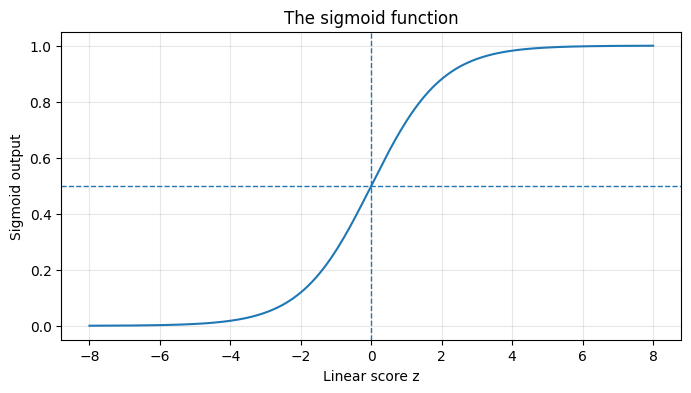

In [5]:
score_grid = np.linspace(-8, 8, 300)
plt.figure(figsize=(8, 4))
plt.plot(score_grid, sigmoid(score_grid))
plt.axhline(0.5, linestyle="--", linewidth=1)
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Linear score z")
plt.ylabel("Sigmoid output")
plt.title("The sigmoid function")
plt.grid(alpha=0.3)
plt.show()

## 5. Turn probability into a yes/no prediction

The model outputs a probability. To make a class prediction, we choose a threshold:

- probability at least 0.5 → predict 1,
- probability below 0.5 → predict 0.

The threshold is a decision rule (you can shift it either sides of 0.5), not part of sigmoid itself.

In [6]:
example_probabilities = np.array([0.12, 0.49, 0.50, 0.83])
example_predictions = (example_probabilities >= 0.5).astype(int)
pd.DataFrame({
    "probability": example_probabilities,
    "predicted_class": example_predictions,
})

,probability,predicted_class
0,0.12,0
1,0.49,0
2,0.50,1
3,0.83,1


## 6. How do we measure a wrong prediction?

We compare the predicted probability \(\hat p\) with the true label \(y\). Logistic regression commonly uses binary cross-entropy:

\[L=-[y\log(\hat p)+(1-y)\log(1-\hat p)]\]

A confident correct prediction gets a small loss. A confident wrong prediction gets a large loss. During training, we minimize the average loss across examples.

In [7]:
def binary_cross_entropy(y_true, probabilities):
    eps = 1e-12
    p = np.clip(probabilities, eps, 1 - eps)
    return -np.mean(
        y_true * np.log(p) + (1 - y_true) * np.log(1 - p)
    )

y_demo = np.array([1, 0, 1, 0])
good_predictions = np.array([0.9, 0.1, 0.8, 0.2])
poor_predictions = np.array([0.2, 0.8, 0.4, 0.7])

print("Loss for good predictions:", binary_cross_entropy(y_demo, good_predictions))
print("Loss for poor predictions:", binary_cross_entropy(y_demo, poor_predictions))

Loss for good predictions: 0.164252033486018
Loss for poor predictions: 1.334784840267073


## 7. What does learning mean?

At first, the model does not know useful weights. We can initialize all weights and the bias to zero.

Then it repeats:
1. make predictions,
2. measure the loss,
3. calculate how each parameter affects the loss,
4. adjust the parameters to reduce loss,
5. repeat.

This process is **gradient descent**. A gradient indicates which direction makes the loss increase fastest. We move in the opposite direction.

## 8. The gradient and update step

For a batch of \(m\) examples:

\[\frac{\partial L}{\partial w}=\frac{1}{m}X^T(\hat p-y)\]

\[\frac{\partial L}{\partial b}=\frac{1}{m}\sum_{i=1}^{m}(\hat p_i-y_i)\]

The update is:

\[w\leftarrow w-\alpha\frac{\partial L}{\partial w},\qquad
b\leftarrow b-\alpha\frac{\partial L}{\partial b}\]

The learning rate \(\alpha\) controls the size of each adjustment. Too small means slow learning; too large can overshoot or become unstable.

In [8]:
# One tiny gradient-descent update, using one feature and three examples.
X_toy = np.array([[1.0], [2.0], [3.0]])
y_toy = np.array([0.0, 0.0, 1.0])
w = np.array([0.0])
b = 0.0
alpha = 0.1

p = sigmoid(X_toy @ w + b)
error = p - y_toy
dw = (X_toy.T @ error) / len(y_toy)
db = np.mean(error)

print("Predictions before:", p)
print("Weight gradient:", dw)
print("Bias gradient:", db)

w = w - alpha * dw
b = b - alpha * db

print("Updated weight:", w)
print("Updated bias:", b)
print("Predictions after:", sigmoid(X_toy @ w + b))

Predictions before: [0.5 0.5 0.5]
Weight gradient: [0.]
Bias gradient: 0.16666666666666666
Updated weight: [0.]
Updated bias: -0.016666666666666666
Predictions after: [0.49583343 0.49583343 0.49583343]


## 9. Why standardize features?

The features have different units and ranges. For example, menu calories are in the thousands, while plate waste is a fraction between 0 and 1.

Standardization uses:

\[x' = \frac{x-\mu}{\sigma}\]

Calculate the mean \(\mu\) and standard deviation \(\sigma\) on training data only. Apply those same values to the test data. This avoids data leakage.

## 10. Train a small model on the actual lunch data

We now combine the pieces. The split is fixed-seed and stratified, and feature scaling is fitted only on the training set.

In [9]:
rng = np.random.default_rng(42)
y_all = df[TARGET].to_numpy(dtype=float)
train_ids, test_ids = [], []

for label in (0, 1):
    ids = np.flatnonzero(y_all == label)
    rng.shuffle(ids)
    n_test = int(round(0.20 * len(ids)))
    test_ids.extend(ids[:n_test])
    train_ids.extend(ids[n_test:])

train_ids = np.array(train_ids)
test_ids = np.array(test_ids)
rng.shuffle(train_ids)
rng.shuffle(test_ids)

X_all = df[FEATURES].to_numpy(dtype=float)
X_train_raw, X_test_raw = X_all[train_ids], X_all[test_ids]
y_train, y_test = y_all[train_ids], y_all[test_ids]

means = X_train_raw.mean(axis=0)
stds = X_train_raw.std(axis=0)
stds[stds == 0] = 1.0
X_train = (X_train_raw - means) / stds
X_test = (X_test_raw - means) / stds

print("Training examples:", len(y_train))
print("Test examples:", len(y_test))

Training examples: 400
Test examples: 100


In [10]:
def stable_bce_from_logits(X, y, weights, bias):
    z = X @ weights + bias
    return float(np.mean(np.logaddexp(0, z) - y * z))

def train_from_scratch(X, y, learning_rate=0.1, iterations=20000):
    weights = np.zeros(X.shape[1])
    bias = 0.0
    history = []

    for _ in range(iterations):
        probabilities = sigmoid(X @ weights + bias)
        errors = probabilities - y
        dw = X.T @ errors / len(y)
        db = np.mean(errors)

        weights -= learning_rate * dw
        bias -= learning_rate * db

        history.append(stable_bce_from_logits(X, y, weights, bias))

    return weights, bias, history

weights, bias, loss_history = train_from_scratch(
    X_train, y_train, learning_rate=0.1
)
print("Final training loss:", loss_history[-1])

Final training loss: 0.40968877664014614


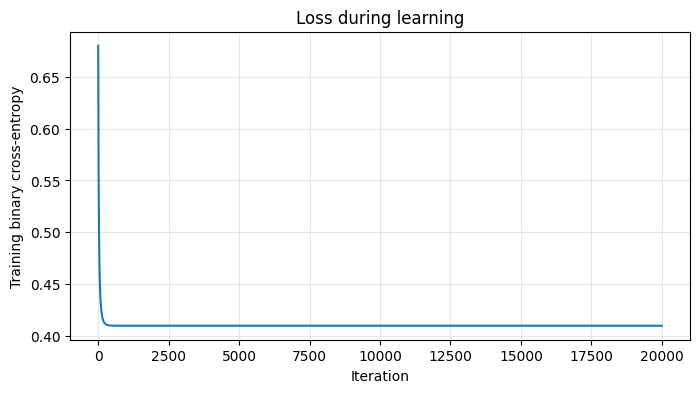

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Iteration")
plt.ylabel("Training binary cross-entropy")
plt.title("Loss during learning")
plt.grid(alpha=0.3)
plt.show()

## 11. Test on lunches the model has not seen

The model predicts probabilities for the held-out test rows. We turn them into labels using the 0.5 threshold and calculate accuracy:

\[accuracy=\frac{\text{number of correct predictions}}{\text{number of test examples}}\]

Accuracy is useful, but it does not explain which examples were wrong. The full pipeline notebook includes a deeper error analysis.

In [12]:
test_probabilities = sigmoid(X_test @ weights + bias)
test_predictions = (test_probabilities >= 0.5).astype(int)
accuracy = np.mean(test_predictions == y_test)

print(f"Test accuracy: {accuracy:.1%}")
display(pd.DataFrame({
    "actual": y_test.astype(int),
    "predicted_probability": test_probabilities,
    "predicted": test_predictions,
}).head(10))

Test accuracy: 85.0%


,actual,predicted_probability,predicted
0,0,0.114883,0
1,1,0.200621,0
2,0,0.080887,0
3,0,0.431033,0
4,1,0.868876,1
5,1,0.378982,0
6,0,0.262136,0
7,0,0.065441,0
8,1,0.294324,0
9,0,0.161676,0


## 12. Key takeaways

- Logistic regression is a classification algorithm.
- A weighted sum creates a score; sigmoid maps it to a probability-like output.
- Binary cross-entropy measures prediction error.
- The gradient tells us how to adjust weights and bias.
- Gradient descent repeats those updates.
- The learning rate controls the update size.
- Feature scaling helps optimization when input features use different scales.
- The test set estimates performance on unseen examples and must not be used to fit the model.